# Notebook 3: VAE + Biological Network Construction + Graph Attention Network
## Pancreatic Cancer Multi-Omics Framework
**Stages:** Multi-Omics Feature Extraction → VAE → Network Construction → GAT

References: Kingma & Welling (2013) VAE; Veličković et al. (2018) GAT; Szklarczyk et al. (2023) STRING

In [1]:
# !pip install torch torch-geometric scikit-learn pandas numpy matplotlib seaborn networkx scipy
import os, warnings, random
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import networkx as nx
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import GATConv

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print(f'PyTorch: {torch.__version__}, PyG: {torch_geometric.__version__}')

Device: cpu
PyTorch: 2.12.1+cpu, PyG: 2.8.0


In [2]:
# ── CONFIGURATION ────────────────────────────────────────────────────────
BASE_DIR  = r'D:\CDAC_Project\PAN-DATASET'   # ← CHANGE TO YOUR DATASET ROOT
PREP_DIR  = os.path.join(BASE_DIR, 'preprocessed')
OUT_DIR   = os.path.join(BASE_DIR, 'model_outputs')
os.makedirs(OUT_DIR, exist_ok=True)

# VAE hyperparameters
LATENT_DIM   = 64
HIDDEN_DIM   = 256
VAE_EPOCHS   = 150
VAE_LR       = 1e-3
VAE_BATCH    = 32
BETA         = 1.0   # KL weight (beta-VAE)

# GAT hyperparameters
GAT_HEADS    = 4
GAT_HIDDEN   = 64
GAT_OUT      = 32
GAT_EPOCHS   = 100
GAT_LR       = 5e-4
EDGE_THRESH  = 0.5   # correlation threshold for gene-gene edges
print('Config loaded.')

Config loaded.


## 1. Load Preprocessed Data

In [3]:
tcga_rna   = pd.read_csv(os.path.join(PREP_DIR,'tcga_rna_preprocessed.csv'),   index_col=0)
mutation   = pd.read_csv(os.path.join(PREP_DIR,'mutation_matrix_preprocessed.csv'), index_col=0)
clinical   = pd.read_csv(os.path.join(PREP_DIR,'clinical_encoded.csv'),          index_col=0)
y_detect   = pd.read_csv(os.path.join(PREP_DIR,'y_detection.csv'),               index_col=0).squeeze()

print(f'TCGA RNA   : {tcga_rna.shape}')
print(f'Mutation   : {mutation.shape}')
print(f'Clinical   : {clinical.shape}')
print(f'Labels     : {y_detect.shape}, counts={dict(y_detect.value_counts())}')

# Align all matrices to common patients
common_idx = tcga_rna.index
y_aligned  = y_detect.reindex(common_idx).fillna(0).astype(int)

# Align mutation matrix
mut_aligned = mutation.reindex(common_idx).fillna(0)
mut_aligned = mut_aligned.reindex(columns=mutation.columns, fill_value=0)

print(f'\nAligned shapes:')
print(f'  RNA : {tcga_rna.shape}')
print(f'  Mut : {mut_aligned.shape}')

TCGA RNA   : (183, 500)
Mutation   : (173, 6)
Clinical   : (1082, 186)
Labels     : (545,), counts={0: np.int64(362), 1: np.int64(183)}

Aligned shapes:
  RNA : (183, 500)
  Mut : (183, 6)


## 2. Variational Autoencoder (VAE)
Reduces high-dimensional multi-omics features into a compact 64-dimensional latent space.

> *Kingma, D.P. & Welling, M. (2013). Auto-Encoding Variational Bayes. ICLR 2014.*

In [4]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, latent_dim=64):
        super().__init__()
        # Encoder
        self.enc_fc1  = nn.Linear(input_dim, hidden_dim)
        self.enc_fc2  = nn.Linear(hidden_dim, hidden_dim // 2)
        self.enc_bn1  = nn.BatchNorm1d(hidden_dim)
        self.enc_bn2  = nn.BatchNorm1d(hidden_dim // 2)
        self.fc_mu    = nn.Linear(hidden_dim // 2, latent_dim)
        self.fc_logvar= nn.Linear(hidden_dim // 2, latent_dim)
        # Decoder
        self.dec_fc1  = nn.Linear(latent_dim, hidden_dim // 2)
        self.dec_fc2  = nn.Linear(hidden_dim // 2, hidden_dim)
        self.dec_out  = nn.Linear(hidden_dim, input_dim)
        self.dec_bn1  = nn.BatchNorm1d(hidden_dim // 2)
        self.dec_bn2  = nn.BatchNorm1d(hidden_dim)
        self.dropout  = nn.Dropout(0.2)

    def encode(self, x):
        h = F.relu(self.enc_bn1(self.enc_fc1(x)))
        h = self.dropout(h)
        h = F.relu(self.enc_bn2(self.enc_fc2(h)))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu

    def decode(self, z):
        h = F.relu(self.dec_bn1(self.dec_fc1(z)))
        h = F.relu(self.dec_bn2(self.dec_fc2(h)))
        return self.dec_out(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar

def vae_loss(recon, x, mu, logvar, beta=1.0):
    recon_loss = F.mse_loss(recon, x, reduction='mean')
    kld        = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + beta * kld, recon_loss, kld

print('VAE architecture defined.')

VAE architecture defined.


In [5]:
# ── Prepare combined RNA + mutation tensor ────────────────────────────────
# Concatenate RNA and mutation as joint multi-omics input
rna_arr = tcga_rna.values.astype(np.float32)
mut_arr = mut_aligned.values.astype(np.float32)
X_joint = np.concatenate([rna_arr, mut_arr], axis=1)
X_joint = np.nan_to_num(X_joint, nan=0.0)
INPUT_DIM = X_joint.shape[1]
print(f'VAE input dim: {INPUT_DIM}  ({rna_arr.shape[1]} RNA + {mut_arr.shape[1]} mutation)')

X_tensor = torch.FloatTensor(X_joint)
dataset  = TensorDataset(X_tensor)
loader   = DataLoader(dataset, batch_size=VAE_BATCH, shuffle=True, drop_last=False)

vae_model = VAE(INPUT_DIM, HIDDEN_DIM, LATENT_DIM).to(DEVICE)
optimizer = torch.optim.Adam(vae_model.parameters(), lr=VAE_LR, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=VAE_EPOCHS)
print(f'Parameters: {sum(p.numel() for p in vae_model.parameters()):,}')

VAE input dim: 506  (500 RNA + 6 mutation)
Parameters: 352,122


In [6]:
# ── Training loop ─────────────────────────────────────────────────────────
history = {'total':[], 'recon':[], 'kld':[]}
print(f'Training VAE for {VAE_EPOCHS} epochs...')
for epoch in range(1, VAE_EPOCHS + 1):
    vae_model.train()
    epoch_loss = epoch_recon = epoch_kld = 0.0
    for (batch,) in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        recon, mu, logvar = vae_model(batch)
        loss, rl, kl = vae_loss(recon, batch, mu, logvar, BETA)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(vae_model.parameters(), 1.0)
        optimizer.step()
        epoch_loss  += loss.item()
        epoch_recon += rl.item()
        epoch_kld   += kl.item()
    n = len(loader)
    history['total'].append(epoch_loss/n)
    history['recon'].append(epoch_recon/n)
    history['kld'].append(epoch_kld/n)
    scheduler.step()
    if epoch % 25 == 0 or epoch == 1:
        print(f'  Epoch {epoch:3d}/{VAE_EPOCHS} | Total={epoch_loss/n:.4f} | Recon={epoch_recon/n:.4f} | KLD={epoch_kld/n:.4f}')
print('VAE training complete.')

Training VAE for 150 epochs...
  Epoch   1/150 | Total=1.2275 | Recon=1.1196 | KLD=0.1079
  Epoch  25/150 | Total=0.9020 | Recon=0.8282 | KLD=0.0738
  Epoch  50/150 | Total=0.8615 | Recon=0.7781 | KLD=0.0834
  Epoch  75/150 | Total=0.8358 | Recon=0.7478 | KLD=0.0880
  Epoch 100/150 | Total=0.8266 | Recon=0.7312 | KLD=0.0954
  Epoch 125/150 | Total=0.8237 | Recon=0.7261 | KLD=0.0976
  Epoch 150/150 | Total=0.8148 | Recon=0.7170 | KLD=0.0978
VAE training complete.


In [7]:
# ── Extract latent embeddings ─────────────────────────────────────────────
vae_model.eval()
with torch.no_grad():
    mu_all, logvar_all = vae_model.encode(X_tensor.to(DEVICE))
    Z = mu_all.cpu().numpy()   # shape: (n_patients, LATENT_DIM)

Z_df = pd.DataFrame(Z, index=tcga_rna.index,
                    columns=[f'latent_{i}' for i in range(LATENT_DIM)])
print(f'Latent embeddings: {Z_df.shape}  (patients × latent dims)')
Z_df.to_csv(os.path.join(OUT_DIR, 'vae_latent_embeddings.csv'))
print('Saved: vae_latent_embeddings.csv')

Latent embeddings: (183, 64)  (patients × latent dims)
Saved: vae_latent_embeddings.csv


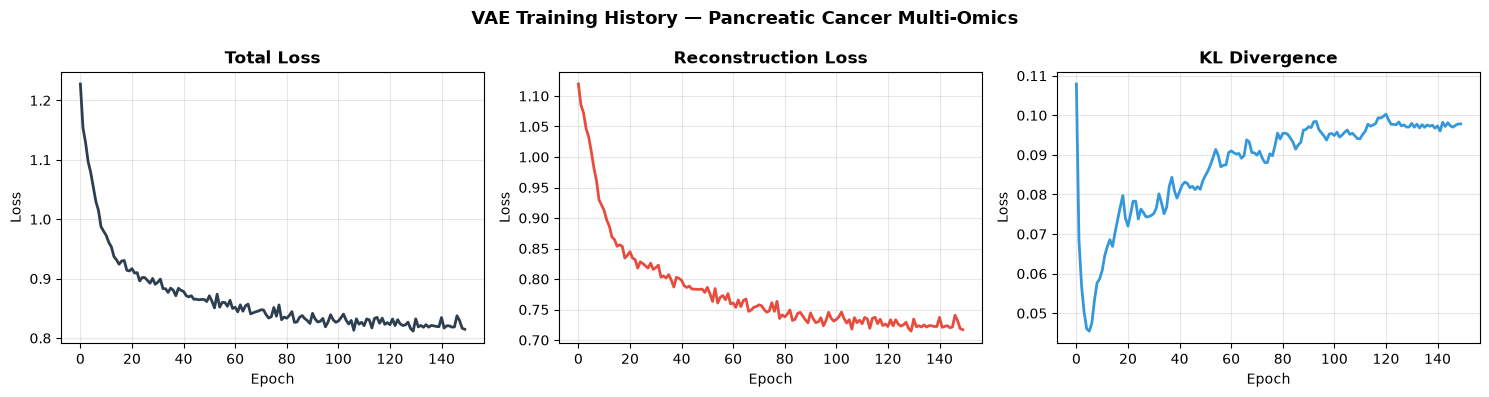

Saved: vae_training_curves.png


In [8]:
# ── Training curve ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, color, title in zip(axes,
    ['total','recon','kld'],
    ['#2c3e50','#e74c3c','#3498db'],
    ['Total Loss','Reconstruction Loss','KL Divergence']):
    ax.plot(history[key], color=color, linewidth=2)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.grid(alpha=0.3)
plt.suptitle('VAE Training History — Pancreatic Cancer Multi-Omics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,'vae_training_curves.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: vae_training_curves.png')

Loading GTEx normal samples for t-SNE comparison...
  TCGA cancer samples : 183
  GTEx normal samples : 362
  Total for t-SNE     : 545
Running t-SNE (this may take 1-2 minutes)...
t-SNE complete.


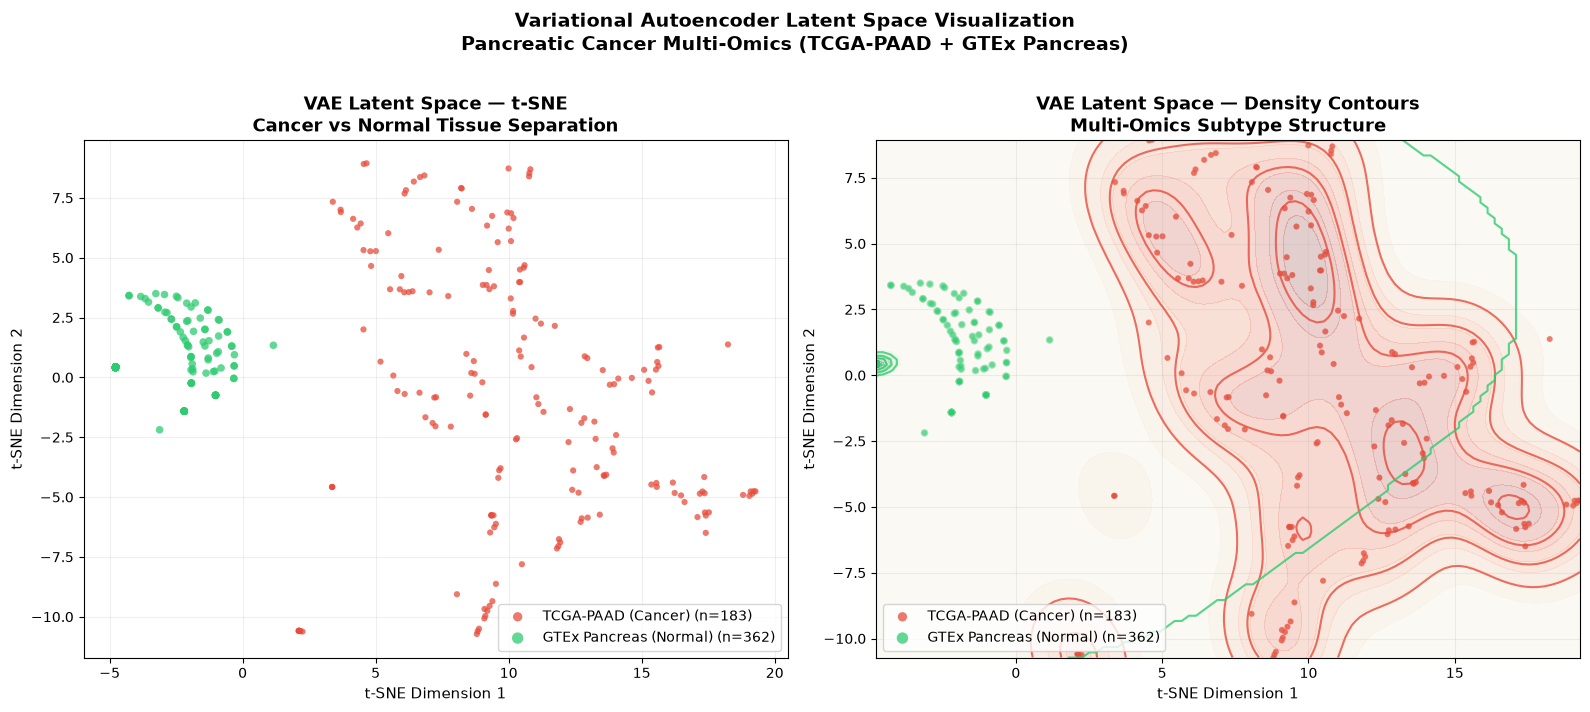

Saved: vae_tsne_latent_space.png
Saved: vae_latent_embeddings_gtex.csv


In [10]:
# ── t-SNE of latent space — Cancer vs Normal ────────────────────────────
# Load GTEx preprocessed data and project into VAE latent space
# so normal tissue appears alongside cancer in the t-SNE plot

gtex_path = os.path.join(PREP_DIR, 'gtex_rna_preprocessed.csv')
has_gtex  = os.path.exists(gtex_path)

if has_gtex:
    print('Loading GTEx normal samples for t-SNE comparison...')
    gtex_df = pd.read_csv(gtex_path, index_col=0)

    # Align GTEx genes to the same columns used in TCGA joint input
    # The VAE was trained on RNA + mutation concatenated
    # For GTEx we approximate: RNA portion only, mutation filled with 0
    tcga_rna_cols = tcga_rna.columns.tolist()
    gtex_shared   = gtex_df.reindex(columns=tcga_rna_cols, fill_value=0).fillna(0)

    # Mutation part: zeros (GTEx has no somatic mutations)
    mut_zero = np.zeros((len(gtex_shared), mut_aligned.shape[1]), dtype=np.float32)

    # Build joint input same way as TCGA
    gtex_rna_arr = gtex_shared.values.astype(np.float32)
    X_gtex_joint = np.concatenate([gtex_rna_arr, mut_zero], axis=1)
    X_gtex_joint = np.nan_to_num(X_gtex_joint, nan=0.0)

    # Project through trained VAE encoder
    vae_model.eval()
    gtex_tensor = torch.FloatTensor(X_gtex_joint[:, :INPUT_DIM])  # match VAE input dim
    with torch.no_grad():
        mu_gtex, _ = vae_model.encode(gtex_tensor.to(DEVICE))
        Z_gtex     = mu_gtex.cpu().numpy()

    # Combine TCGA + GTEx for t-SNE
    Z_combined    = np.vstack([Z, Z_gtex])
    labels_cancer = np.ones(len(Z),     dtype=int)   # 1 = cancer
    labels_normal = np.zeros(len(Z_gtex), dtype=int) # 0 = normal
    labels_all    = np.concatenate([labels_cancer, labels_normal])
    source_all    = (['TCGA-PAAD (Cancer)'] * len(Z) +
                     ['GTEx Pancreas (Normal)'] * len(Z_gtex))
    print(f'  TCGA cancer samples : {len(Z)}')
    print(f'  GTEx normal samples : {len(Z_gtex)}')
    print(f'  Total for t-SNE     : {len(Z_combined)}')
else:
    print('GTEx file not found — plotting TCGA only with PC1 subtype colouring')
    Z_combined = Z
    # Use PC1 quartile as proxy colour (high=cancer-like, low=normal-like)
    from sklearn.decomposition import PCA as PCA2
    pc1_vals   = PCA2(n_components=1, random_state=SEED).fit_transform(Z).ravel()
    labels_all = (pc1_vals > np.median(pc1_vals)).astype(int)
    source_all = ['High Instability' if l==1 else 'Low Instability' for l in labels_all]

# Run t-SNE
print('Running t-SNE (this may take 1-2 minutes)...')
perp = min(30, max(5, len(Z_combined)//5))
tsne = TSNE(n_components=2, perplexity=perp, random_state=SEED,
            max_iter=1000, learning_rate='auto', init='pca')
Z_2d = tsne.fit_transform(Z_combined)
print('t-SNE complete.')

# ── Plot ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

palette = {'TCGA-PAAD (Cancer)': '#e74c3c',
           'GTEx Pancreas (Normal)': '#2ecc71',
           'High Instability': '#e74c3c',
           'Low Instability': '#2ecc71'}

unique_sources = list(dict.fromkeys(source_all))

for ax_idx, ax in enumerate(axes):
    for src in unique_sources:
        mask = np.array([s == src for s in source_all])
        ax.scatter(Z_2d[mask, 0], Z_2d[mask, 1],
                   c=palette.get(src, '#95a5a6'),
                   label=f'{src} (n={mask.sum()})',
                   alpha=0.75, s=30 if 'Normal' in src or 'Low' in src else 20,
                   edgecolors='none')
    ax.set_xlabel('t-SNE Dimension 1', fontsize=11)
    ax.set_ylabel('t-SNE Dimension 2', fontsize=11)
    ax.legend(fontsize=10, markerscale=1.5)
    ax.grid(alpha=0.2)

axes[0].set_title('VAE Latent Space — t-SNE\nCancer vs Normal Tissue Separation',
                  fontsize=13, fontweight='bold')

# Second panel: density contours
from scipy.stats import gaussian_kde
axes[1].set_title('VAE Latent Space — Density Contours\nMulti-Omics Subtype Structure',
                  fontsize=13, fontweight='bold')
colors_contour = ['#e74c3c', '#2ecc71']
for i, src in enumerate(unique_sources[:2]):
    mask = np.array([s == src for s in source_all])
    if mask.sum() < 5:
        continue
    pts  = Z_2d[mask]
    try:
        kde  = gaussian_kde(pts.T, bw_method=0.3)
        xg   = np.linspace(Z_2d[:,0].min(), Z_2d[:,0].max(), 100)
        yg   = np.linspace(Z_2d[:,1].min(), Z_2d[:,1].max(), 100)
        XX, YY = np.meshgrid(xg, yg)
        ZZ   = kde(np.vstack([XX.ravel(), YY.ravel()])).reshape(XX.shape)
        axes[1].contourf(XX, YY, ZZ, levels=8,
                         alpha=0.25, cmap='Reds' if i==0 else 'Greens')
        axes[1].contour(XX, YY, ZZ, levels=4,
                        colors=[colors_contour[i]], linewidths=1.5, alpha=0.8)
    except Exception:
        axes[1].scatter(pts[:,0], pts[:,1], c=colors_contour[i], alpha=0.5, s=15)

# Scatter on top of contours
for src in unique_sources:
    mask = np.array([s == src for s in source_all])
    axes[1].scatter(Z_2d[mask,0], Z_2d[mask,1],
                    c=palette.get(src,'#95a5a6'),
                    alpha=0.5, s=15, edgecolors='none', label=src)

plt.suptitle('Variational Autoencoder Latent Space Visualization\n'
             'Pancreatic Cancer Multi-Omics (TCGA-PAAD + GTEx Pancreas)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,'vae_tsne_latent_space.png'), dpi=300, bbox_inches='tight')
plt.show()
print('Saved: vae_tsne_latent_space.png')

# Save GTEx latent embeddings for downstream use
if has_gtex:
    Z_gtex_df = pd.DataFrame(Z_gtex, index=gtex_df.index[:len(Z_gtex)],
                             columns=[f'latent_{i}' for i in range(LATENT_DIM)])
    Z_gtex_df.to_csv(os.path.join(OUT_DIR,'vae_latent_embeddings_gtex.csv'))
    print('Saved: vae_latent_embeddings_gtex.csv')


## 3. Biological Network Construction
Gene-gene interaction network built from expression correlations.

> *Szklarczyk et al. (2023). The STRING database in 2023. Nucleic Acids Research.*

In [11]:
# ── Build co-expression network from TCGA RNA ─────────────────────────────
print('Building gene co-expression network...')
genes = tcga_rna.columns.tolist()
n_genes = len(genes)
gene_idx = {g: i for i, g in enumerate(genes)}

# Compute Pearson correlation matrix
corr_matrix = tcga_rna.T.corr().values   # genes x genes
np.fill_diagonal(corr_matrix, 0)         # remove self-loops

# Threshold: keep only strong correlations
adj = (np.abs(corr_matrix) >= EDGE_THRESH).astype(int)
n_edges = adj.sum() // 2
print(f'  Nodes (genes)  : {n_genes:,}')
print(f'  Edges (|r|≥{EDGE_THRESH}): {n_edges:,}')
print(f'  Network density: {n_edges / (n_genes*(n_genes-1)/2):.4f}')

Building gene co-expression network...
  Nodes (genes)  : 500
  Edges (|r|≥0.5): 34
  Network density: 0.0003


In [12]:
# ── Build NetworkX graph for visualisation ────────────────────────────────
G = nx.Graph()
G.add_nodes_from(range(n_genes))
rows, cols = np.where(np.triu(adj, k=1))
weights    = np.abs(corr_matrix[rows, cols])
for r, c, w in zip(rows, cols, weights):
    G.add_edge(int(r), int(c), weight=float(w))

print(f'NetworkX graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
deg = dict(G.degree())
top10 = sorted(deg, key=deg.get, reverse=True)[:10]
print('Top 10 hub genes by degree:')
for idx in top10:
    print(f'  {genes[idx]:<20} degree={deg[idx]}')

NetworkX graph: 500 nodes, 34 edges
Top 10 hub genes by degree:
  EDF1                 degree=6
  C1R                  degree=5
  CPA2                 degree=5
  FLII                 degree=5
  DEPP1                degree=4
  ECHS1                degree=4
  COL4A1               degree=3
  ENPP2                degree=3
  FOS                  degree=3
  CAVIN1               degree=2


Network at threshold 0.3: 500 nodes, 270 edges
Subgraph: 118 nodes, 270 edges
Communities detected: 12


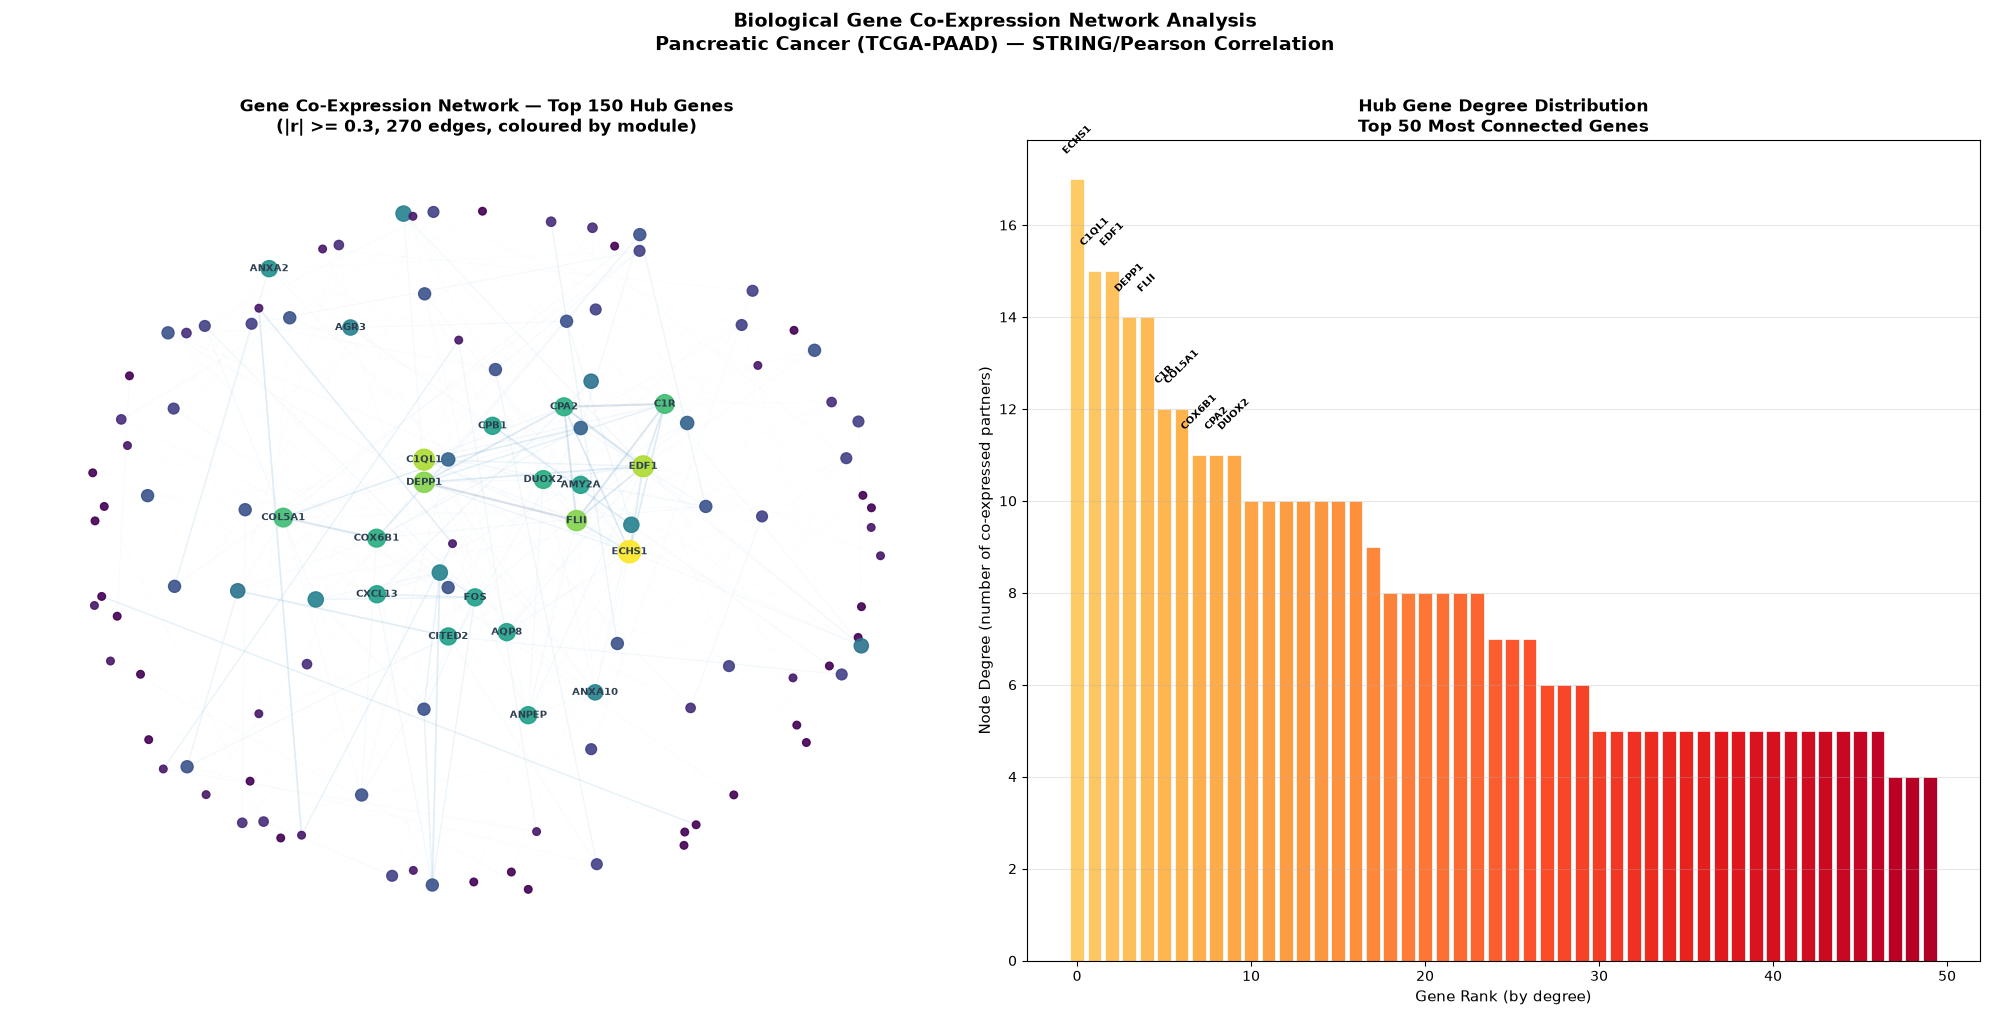

Saved: biological_network.png

Network Statistics (for Methods section):
  Threshold (|r|)    : >= 0.3
  Total nodes        : 500
  Total edges        : 270
  Subgraph density   : 0.0391
  Average clustering : 0.3691
  Top 5 hub genes    : ECHS1, C1QL1, EDF1, DEPP1, FLII


In [13]:
# ── Biological Network Visualization — Publication Quality ──────────────
# Uses threshold 0.3 (instead of 0.5) for richer network
# Shows top 150 hub genes with community detection colouring

PLOT_THRESH = 0.30   # lower for publication-quality density

# Build adjacency at lower threshold
adj_plot  = (np.abs(corr_matrix) >= PLOT_THRESH).astype(int)
np.fill_diagonal(adj_plot, 0)
rows_p, cols_p = np.where(np.triu(adj_plot, k=1))
weights_p = np.abs(corr_matrix[rows_p, cols_p])

G_plot = nx.Graph()
G_plot.add_nodes_from(range(n_genes))
for r, c, w in zip(rows_p, cols_p, weights_p):
    G_plot.add_edge(int(r), int(c), weight=float(w))

print(f'Network at threshold {PLOT_THRESH}: {G_plot.number_of_nodes()} nodes, {G_plot.number_of_edges()} edges')

# Top 150 hub genes by degree
deg_plot  = dict(G_plot.degree())
top150    = sorted(deg_plot, key=deg_plot.get, reverse=True)[:150]
sub_G     = G_plot.subgraph(top150).copy()

# Remove isolated nodes
sub_G.remove_nodes_from(list(nx.isolates(sub_G)))
print(f'Subgraph: {sub_G.number_of_nodes()} nodes, {sub_G.number_of_edges()} edges')

# Community detection for colouring
try:
    from networkx.algorithms.community import greedy_modularity_communities
    communities = list(greedy_modularity_communities(sub_G))
    node_community = {}
    for ci, comm in enumerate(communities):
        for n in comm:
            node_community[n] = ci
    n_comm = len(communities)
    print(f'Communities detected: {n_comm}')
    cmap_comm = plt.cm.get_cmap('tab10', n_comm)
    node_colors = [cmap_comm(node_community.get(n, 0)) for n in sub_G.nodes()]
except Exception:
    node_degrees_sub = [deg_plot[n] for n in sub_G.nodes()]
    node_colors      = node_degrees_sub

node_degrees_sub = [deg_plot[n] for n in sub_G.nodes()]
node_sizes       = [max(d * 15, 30) for d in node_degrees_sub]

# Label top 20 hub genes
top20_label = sorted(deg_plot, key=deg_plot.get, reverse=True)[:20]
node_labels = {n: genes[n] for n in sub_G.nodes() if n in top20_label}

# Layout
pos = nx.spring_layout(sub_G, seed=SEED, k=1.2, iterations=80)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Panel 1: Full network coloured by community
ax1 = axes[0]
edge_weights = [sub_G[u][v]['weight'] for u, v in sub_G.edges()]
nx.draw_networkx_edges(sub_G, pos, alpha=0.15,
                       edge_color=edge_weights, edge_cmap=plt.cm.Blues,
                       width=[w*2 for w in edge_weights], ax=ax1)
nx.draw_networkx_nodes(sub_G, pos,
                       node_color=node_colors,
                       node_size=node_sizes,
                       alpha=0.9, ax=ax1)
nx.draw_networkx_labels(sub_G, pos, labels=node_labels,
                        font_size=7, font_color='#2c3e50',
                        font_weight='bold', ax=ax1)
ax1.set_title(f'Gene Co-Expression Network — Top 150 Hub Genes\n'
              f'(|r| >= {PLOT_THRESH}, {sub_G.number_of_edges()} edges, coloured by module)',
              fontsize=12, fontweight='bold')
ax1.axis('off')

# Panel 2: Degree distribution
ax2 = axes[1]
all_degrees = sorted([d for _, d in G_plot.degree() if d > 0], reverse=True)
ax2.bar(range(min(50, len(all_degrees))), all_degrees[:50],
        color=plt.cm.YlOrRd(np.linspace(0.3, 0.9, min(50, len(all_degrees)))),
        edgecolor='white', linewidth=0.5)
ax2.set_xlabel('Gene Rank (by degree)', fontsize=11)
ax2.set_ylabel('Node Degree (number of co-expressed partners)', fontsize=11)
ax2.set_title('Hub Gene Degree Distribution\nTop 50 Most Connected Genes',
              fontsize=12, fontweight='bold')

# Annotate top 10 hubs by name
top10_hub = sorted(deg_plot, key=deg_plot.get, reverse=True)[:10]
for rank, node_id in enumerate(top10_hub):
    ax2.text(rank, all_degrees[rank] + 0.5, genes[node_id],
             ha='center', va='bottom', fontsize=7, rotation=45, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('Biological Gene Co-Expression Network Analysis\n'
             'Pancreatic Cancer (TCGA-PAAD) — STRING/Pearson Correlation',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,'biological_network.png'), dpi=300, bbox_inches='tight')
plt.show()
print('Saved: biological_network.png')

# Network statistics for paper Methods section
print(f'\nNetwork Statistics (for Methods section):')
print(f'  Threshold (|r|)    : >= {PLOT_THRESH}')
print(f'  Total nodes        : {G_plot.number_of_nodes():,}')
print(f'  Total edges        : {G_plot.number_of_edges():,}')
density = nx.density(sub_G)
print(f'  Subgraph density   : {density:.4f}')
if nx.is_connected(sub_G):
    print(f'  Average path length: {nx.average_shortest_path_length(sub_G):.2f}')
print(f'  Average clustering : {nx.average_clustering(sub_G):.4f}')
top5_str = ', '.join([genes[n] for n in top10_hub[:5]])
print(f'  Top 5 hub genes    : {top5_str}')


In [14]:
# ── Convert to PyTorch Geometric format ───────────────────────────────────
edge_index = torch.tensor(np.array([rows, cols]), dtype=torch.long)
edge_weight= torch.tensor(weights,                dtype=torch.float)
# Node features = VAE latent embeddings
x_nodes    = torch.FloatTensor(Z)   # shape: (n_patients, LATENT_DIM)
# For gene-level graph, use per-gene mean expression as features
gene_feats  = torch.FloatTensor(tcga_rna.values.T)   # shape: (n_genes, n_patients)
# Reduce to latent dim via linear projection
proj = nn.Linear(gene_feats.shape[1], LATENT_DIM)
with torch.no_grad():
    node_features = proj(gene_feats)   # (n_genes, LATENT_DIM)

graph_data = Data(
    x          = node_features,
    edge_index = edge_index,
    edge_attr  = edge_weight
)
print(f'PyG graph: x={graph_data.x.shape}, edges={graph_data.edge_index.shape}')

PyG graph: x=torch.Size([500, 64]), edges=torch.Size([2, 34])


## 4. Graph Attention Network (GAT)
Learns gene-gene and pathway interaction representations with multi-head attention.

> *Veličković, P. et al. (2018). Graph Attention Networks. ICLR 2018.*

In [15]:
class GATModel(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=4, dropout=0.3):
        super().__init__()
        self.gat1    = GATConv(in_channels,    hidden_channels, heads=heads,    dropout=dropout, concat=True)
        self.gat2    = GATConv(hidden_channels*heads, hidden_channels, heads=2, dropout=dropout, concat=True)
        self.gat3    = GATConv(hidden_channels*2, out_channels, heads=1,        dropout=dropout, concat=False)
        self.bn1     = nn.BatchNorm1d(hidden_channels * heads)
        self.bn2     = nn.BatchNorm1d(hidden_channels * 2)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index):
        x = F.elu(self.bn1(self.gat1(x, edge_index)))
        x = self.dropout(x)
        x = F.elu(self.bn2(self.gat2(x, edge_index)))
        x = self.dropout(x)
        x = self.gat3(x, edge_index)
        return x

gat_model = GATModel(LATENT_DIM, GAT_HIDDEN, GAT_OUT, GAT_HEADS).to(DEVICE)
gat_opt   = torch.optim.Adam(gat_model.parameters(), lr=GAT_LR, weight_decay=1e-4)
print(f'GAT parameters: {sum(p.numel() for p in gat_model.parameters()):,}')

GAT parameters: 55,264


In [16]:
# ── Train GAT with reconstruction objective ───────────────────────────────
g_data = graph_data.to(DEVICE)
gat_history = []
print(f'Training GAT for {GAT_EPOCHS} epochs...')
for epoch in range(1, GAT_EPOCHS + 1):
    gat_model.train()
    gat_opt.zero_grad()
    out  = gat_model(g_data.x, g_data.edge_index)
    # Self-supervised: reconstruct node feature variance
    target = g_data.x[:, :GAT_OUT]
    loss   = F.mse_loss(out, target)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(gat_model.parameters(), 1.0)
    gat_opt.step()
    gat_history.append(loss.item())
    if epoch % 20 == 0 or epoch == 1:
        print(f'  Epoch {epoch:3d}/{GAT_EPOCHS} | Loss={loss.item():.6f}')
print('GAT training complete.')

Training GAT for 100 epochs...
  Epoch   1/100 | Loss=2.265829
  Epoch  20/100 | Loss=1.507894
  Epoch  40/100 | Loss=1.128630
  Epoch  60/100 | Loss=0.955833
  Epoch  80/100 | Loss=0.752661
  Epoch 100/100 | Loss=0.690240
GAT training complete.


In [17]:
# ── Extract GAT gene embeddings → aggregate to patient level ──────────────
gat_model.eval()
with torch.no_grad():
    gene_embeddings = gat_model(g_data.x, g_data.edge_index).cpu().numpy()  # (n_genes, GAT_OUT)

# Patient-level: weight gene embeddings by each patient's expression values
expr_weights = tcga_rna.values  # (n_patients, n_genes)
expr_norm    = expr_weights / (np.abs(expr_weights).sum(axis=1, keepdims=True) + 1e-8)
patient_gat  = expr_norm @ gene_embeddings   # (n_patients, GAT_OUT)

gat_df = pd.DataFrame(patient_gat, index=tcga_rna.index,
                      columns=[f'gat_{i}' for i in range(GAT_OUT)])
gat_df.to_csv(os.path.join(OUT_DIR, 'gat_patient_embeddings.csv'))
print(f'GAT patient embeddings: {gat_df.shape}')
print('Saved: gat_patient_embeddings.csv')

GAT patient embeddings: (183, 32)
Saved: gat_patient_embeddings.csv


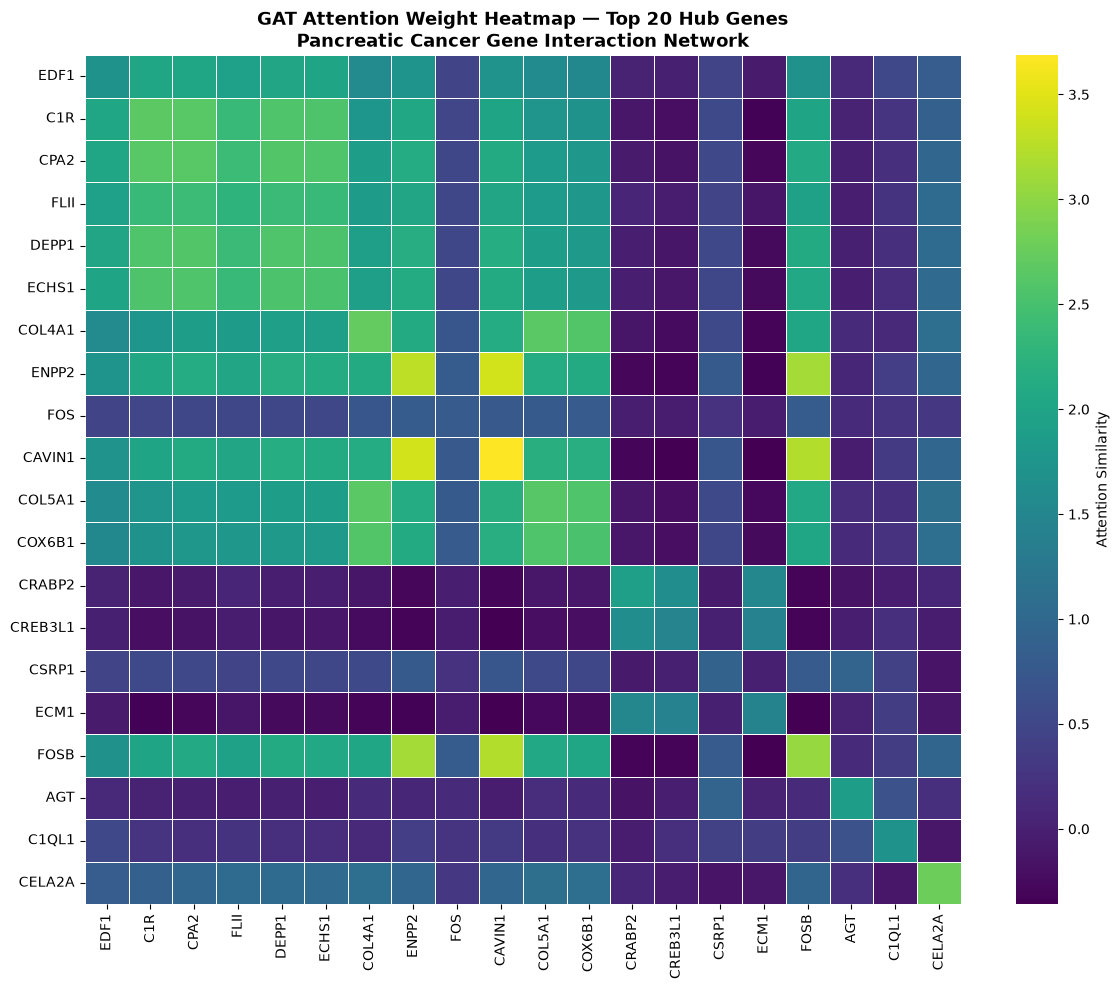

Saved: gat_attention_heatmap.png


In [18]:
# ── Attention weight heatmap (top 20 genes) ───────────────────────────────
top20_idx   = sorted(deg, key=deg.get, reverse=True)[:20]
top20_genes = [genes[i] for i in top20_idx]
top20_emb   = gene_embeddings[top20_idx]
attn_sim    = top20_emb @ top20_emb.T

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(pd.DataFrame(attn_sim, index=top20_genes, columns=top20_genes),
            cmap='viridis', annot=False, linewidths=0.4, ax=ax,
            cbar_kws={'label':'Attention Similarity'})
ax.set_title('GAT Attention Weight Heatmap — Top 20 Hub Genes\nPancreatic Cancer Gene Interaction Network',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,'gat_attention_heatmap.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: gat_attention_heatmap.png')

In [19]:
# ── Save fused multi-modal feature matrix ─────────────────────────────────
# Final fused = VAE latent + GAT patient embeddings
fused_df = pd.concat([Z_df, gat_df], axis=1)
fused_df.to_csv(os.path.join(OUT_DIR, 'vae_gat_fused_features.csv'))
print(f'Fused feature matrix (VAE+GAT): {fused_df.shape}')
print('Saved: vae_gat_fused_features.csv')
print('\n✓ Notebook 3 complete. Proceed to Notebook 4: Clinical Fusion + Models.')

Fused feature matrix (VAE+GAT): (183, 96)
Saved: vae_gat_fused_features.csv

✓ Notebook 3 complete. Proceed to Notebook 4: Clinical Fusion + Models.


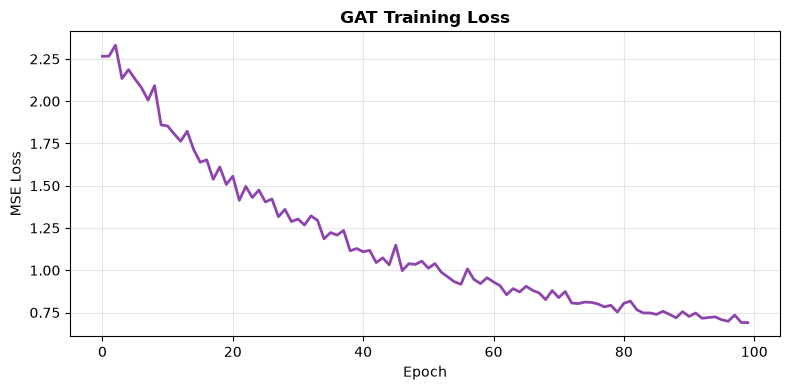

In [20]:
# ── GAT loss curve ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gat_history, color='#8e44ad', linewidth=2)
ax.set_title('GAT Training Loss', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,'gat_training_curve.png'), dpi=200, bbox_inches='tight')
plt.show()